In [2]:
import argparse
import json
import math
import os
import random
from dataclasses import dataclass, field

import nibabel as nib
import numpy as np
import torch
import torch.nn.functional as F

import cornucopia as cc
# `Uniform(a, b)` is a cornucopia "sampler": every time a transform needs a
# random value it calls the sampler, e.g. Uniform(0, 1)() -> 0.37, and
# Uniform(0, 1)(3) -> [0.12, 0.88, 0.45] (one value per tissue).
from cornucopia.random import Uniform
# Low-level resampling helpers (wrap torch.nn.functional.grid_sample).
from cornucopia.utils import warps


import sys
sys.path.append("/home/agustin/phd/synthesis/utils")

import util_freesurfer_segmentation as ufs
import matplotlib.pyplot as plt


In [3]:
# ===========================================================================
# 2. Label super-resolution (offline)
# ===========================================================================
# Goal: turn a blocky 1 mm label map into a smooth 0.25 mm label map, where
# boundaries are no longer staircases of 1 mm cubes.
#
# Paper recipe (Sec. 3.2.1), per label k:
#     binary mask (lab == k)          -> "one-hot channel k"
#     Sinc interpolation to 0.25 mm   -> smooth, band-limited "soft mask"
#     Gaussian smoothing (0.5 mm)     -> removes Sinc ringing
# then, at each HR voxel, pick the label whose soft mask is largest (argmax).
#
# 1D intuition (one row of voxels, 1 mm, two labels):
#     label  :  A   A   A   B   B
#     mask A :  1   1   1   0   0
#     mask B :  0   0   0   1   1
#   after upsampling x4 and smoothing (values roughly):
#     mask A :  1 1 1 1 1 1 1 1 1 .9 .7 .5 .3 .1 0 0 ...
#     mask B :  0 0 0 0 0 0 0 0 0 .1 .3 .5 .7 .9 1 1 ...
#   argmax  :  A A A A A A A A A  A  A  ?  B  B B B ...
#   -> the A/B boundary is placed with 0.25 mm precision, and in 3D curved
#      boundaries become smooth instead of staircased.

def _sinc_upsample_smooth(x, factor, sigma_mm, out_voxel_mm):
    """
    Band-limited (Sinc) upsampling by zero-padding the centred spectrum,
    combined with a Gaussian smoothing applied in the Fourier domain.
    Output voxel `j` sits at input coordinate `j / factor`.

    Why the Fourier domain?
    -----------------------
    * Sinc interpolation == "keep all the frequencies the image has, add no
      new ones". In Fourier space that is literally: copy the spectrum into
      the centre of a bigger array full of zeros, then inverse FFT.
    * Gaussian smoothing == convolution with a Gaussian == multiplication of
      the spectrum by another Gaussian. So both steps cost one FFT + one
      inverse FFT, instead of a huge 3D convolution at 0.25 mm.

    Parameters
    ----------
    x : (X, Y, Z) float tensor     binary mask of one label (0./1.)
    factor : int                   upsampling factor (4: 1 mm -> 0.25 mm)
    sigma_mm : float               Gaussian sigma in mm (0 = no smoothing)
    out_voxel_mm : float           output voxel size in mm (0.25)

    Returns
    -------
    y : (X*factor, Y*factor, Z*factor) float tensor   soft mask
    """
    shape = x.shape                                  # e.g. (180, 222, 195)
    new_shape = [s * factor for s in shape]          # e.g. (720, 888, 780)

    # Forward FFT; fftshift moves frequency 0 ("DC", the mean) to the centre
    # of the array so the spectrum is symmetric around the middle.
    X = torch.fft.fftshift(torch.fft.fftn(x))

    # Bigger, empty (all-zero) spectrum. The zeros are the "new" high
    # frequencies -> they stay zero -> no new detail is invented.
    Xp = torch.zeros(new_shape, dtype=X.dtype, device=X.device)

    # keep the DC component (index s//2 after fftshift) aligned
    # Paste the small spectrum in the middle of the big one so that DC lands
    # on the DC position of the big array (n//2).
    #   1D example: s = 4, factor = 4 -> n = 16
    #     small DC index = 4//2 = 2 ; big DC index = 16//2 = 8
    #     slice(8 - 2, 8 - 2 + 4) = slice(6, 10)  -> small[2] lands at big[8]
    slicer = tuple(slice(n // 2 - s // 2, n // 2 - s // 2 + s)
                   for n, s in zip(new_shape, shape))
    Xp[slicer] = X
    del X                                            # free GPU memory

    if sigma_mm:
        # frequency grid of the HR volume in cycles/mm
        # The Fourier transform of a Gaussian with std `sigma` (mm) is
        #     G(f) = exp(-2 * pi^2 * sigma^2 * f^2)       (f in cycles/mm)
        # A 3D Gaussian is separable: G(fx, fy, fz) = G(fx) G(fy) G(fz),
        # so we multiply by a 1D profile along each axis in turn.
        #
        # Example with sigma = 0.5 mm:
        #   f = 0    (mean intensity)        -> G = 1.00 (kept)
        #   f = 0.25 cycles/mm (4 mm detail) -> G = 0.73
        #   f = 0.5  cycles/mm (1 mm Nyquist)-> G = 0.29 (ringing damped)
        for d, n in enumerate(new_shape):
            # fftfreq gives the frequency of every FFT bin; shift it so it
            # matches the shifted spectrum (0 in the middle).
            f = torch.fft.fftshift(torch.fft.fftfreq(
                n, d=out_voxel_mm, device=x.device))
            g = torch.exp(-2 * (math.pi * sigma_mm * f) ** 2)
            # Reshape the 1D profile so it broadcasts along axis d only:
            #   d=0 -> (n,1,1) ; d=1 -> (1,n,1) ; d=2 -> (1,1,n)
            view = [1] * len(new_shape)
            view[d] = n
            Xp *= g.view(view)

    # Undo the shift, inverse FFT, keep the real part (the imaginary part is
    # only numerical round-off for a real input).
    y = torch.fft.ifftn(torch.fft.ifftshift(Xp)).real

    # Amplitude correction: ifftn divides by the number of voxels, which is
    # factor^3 = 64 times larger than before. Without this, a mask of 1s
    # would come back as 1/64. (Not strictly needed for argmax, which only
    # compares channels, but keeps values interpretable: inside ~1, outside
    # ~0, boundary ~0.5.)
    return y * (factor ** len(shape))
  
  
def linear_upsample_smooth(x, factor, sigma_mm, out_voxel_mm):
    """
    Linear upsampling (torch.nn.functional.interpolate) + Gaussian smoothing.
    Output voxel `j` sits at input coordinate `j / factor`.
    """
    # Linear upsampling (trilinear interpolation)
    y = F.interpolate(
        x[None, None], scale_factor=factor, mode='trilinear',
        align_corners=False)[0, 0]
    
    # #apply Gaussian smoothing in image somain
    # if sigma_mm:
    #     # Convert sigma from mm to voxels in the HR space
    #     sigma_vox = sigma_mm / out_voxel_mm
    #     # Create a Gaussian kernel
    #     size = int(2 * round(3 * sigma_vox) + 1)  # Kernel size: 6*sigma + 1
    #     coords = torch.arange(size, dtype=torch.float32, device=x.device) - (size - 1) / 2
    #     g = torch.exp(-0.5 * (coords / sigma_vox) ** 2)
    #     g /= g.sum()  # Normalize the kernel

    #     # Apply Gaussian smoothing in each dimension
    #     for dim in range(3):
    #         y = F.conv1d(y.unsqueeze(0).unsqueeze(0), g.view(1, 1, -1), padding=size // 2, groups=1).squeeze(0).squeeze(0)
    #         y = y.transpose(dim, -1)  # Move the smoothed dimension to the end for the next iteration
        
    return y





def super_resolve_labels(lab, nb_labels, factor, voxel_mm, sigma_mm=0.5, strategy='sinc'):
    """
    One-hot -> Sinc upsampling -> Gaussian smoothing -> argmax (Sec. 3.2.1).
    Channels are processed one at a time and a running argmax is kept, so
    the full HR one-hot volume is never held in memory.

    Memory reasoning
    ----------------
    HR volume here: 720 x 888 x 780 = 499 M voxels.
    Full one-hot, 14 channels x 4 bytes  -> 28 GB
    Running argmax: 1 float "best" + 1 uint8 "out" + 1 channel -> ~5 GB

    Running argmax, 1-voxel example (3 labels):
        k=0: y=0.1 -> best=0.1, out=0
        k=1: y=0.7 -> 0.7 > 0.1 -> best=0.7, out=1
        k=2: y=0.2 -> 0.2 < 0.7 -> unchanged
        final label = 1   (same result as argmax([0.1, 0.7, 0.2]))
    """
    out_voxel_mm = voxel_mm / factor                 # 1 / 4 = 0.25 mm
    best = None   # highest soft-mask value seen so far, per HR voxel
    out = None    # label that produced it, per HR voxel
    for k in range(nb_labels):
        mask = (lab == k)                            # one-hot channel k
        if not mask.any():                           # label absent (e.g. vessel)
            continue
        if strategy == 'sinc':
            y = _sinc_upsample_smooth(mask.float(), factor, sigma_mm,
                                      out_voxel_mm)
        elif strategy == 'linear':
            y = linear_upsample_smooth(mask.float(), factor, sigma_mm,
                                       out_voxel_mm)
        if best is None:
            # first present label: everything is initially assigned to it
            best = y
            out = torch.full_like(y, k, dtype=torch.uint8)
        else:
            better = y > best                        # where label k wins
            out.masked_fill_(better, k)              # out[better] = k
            torch.maximum(best, y, out=best)         # in-place, no new memory
        del y
    return out


In [4]:
seg_fpath = "/home/agustin/phd/synthseg_nextbrain/project/dev/wp3/augmentation/pipeline/data/inputs/seg.nii.gz"
seg = nib.load(seg_fpath).get_fdata()

seg = ufs.merge_seg96_to_seg3(seg) #map to 0,1,2,3
middle_slice = seg.shape[2] // 2


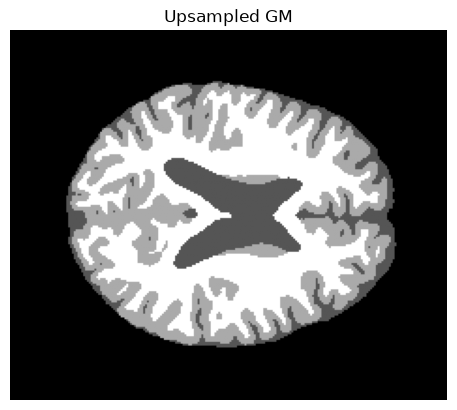

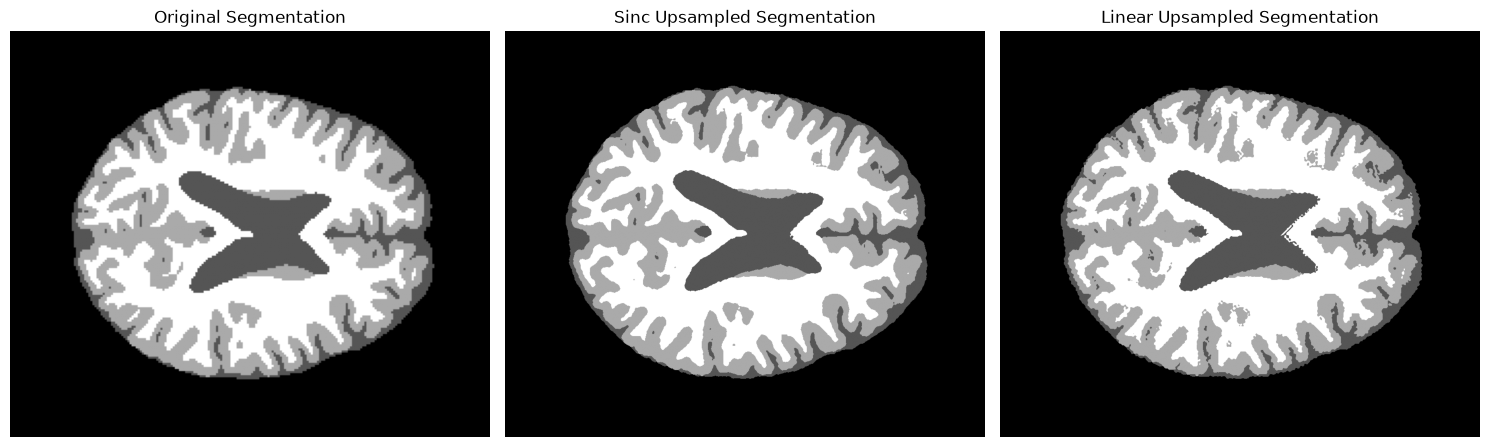

In [5]:
plt.imshow(seg[..., middle_slice], cmap='gray')
plt.title(f'Upsampled GM')
plt.axis('off')
plt.show()



seg_up_sinc = super_resolve_labels(torch.from_numpy(seg), nb_labels=4, factor=4, voxel_mm=1, sigma_mm=0.5, strategy='sinc')
seg_up_linear = super_resolve_labels(torch.from_numpy(seg), nb_labels=4, factor=4, voxel_mm=1, sigma_mm=None, strategy='sinc')
# seg_up_linear = super_resolve_labels(torch.from_numpy(seg), nb_labels=4, factor=4, voxel_mm=1, sigma_mm=0.5, strategy='linear')
middle_slice_up = seg_up_sinc.shape[2] // 2
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(seg[..., middle_slice], cmap='gray')
axes[0].set_title('Original Segmentation')
axes[0].axis('off')
axes[1].imshow(seg_up_sinc[..., middle_slice_up], cmap='gray')
axes[1].set_title('Sinc Upsampled Segmentation')
axes[1].axis('off')
axes[2].imshow(seg_up_linear[..., middle_slice_up], cmap='gray')
axes[2].set_title('Linear Upsampled Segmentation')
axes[2].axis('off')
plt.tight_layout()
plt.show()


Seg shape: (197, 233, 189, 4)


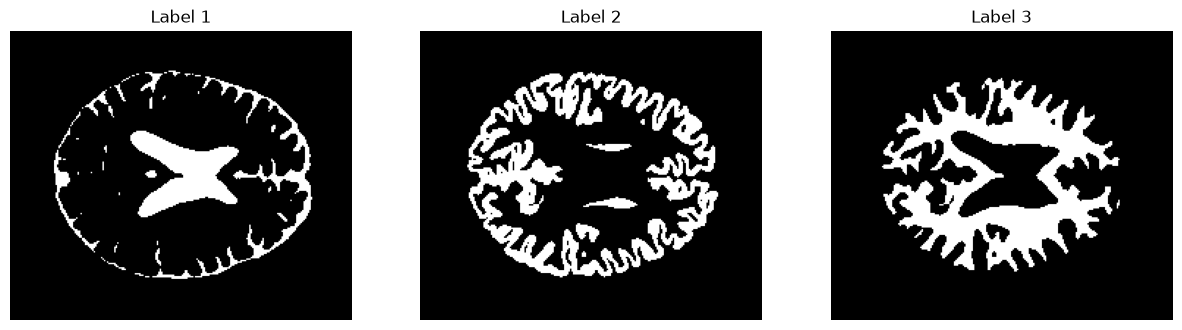

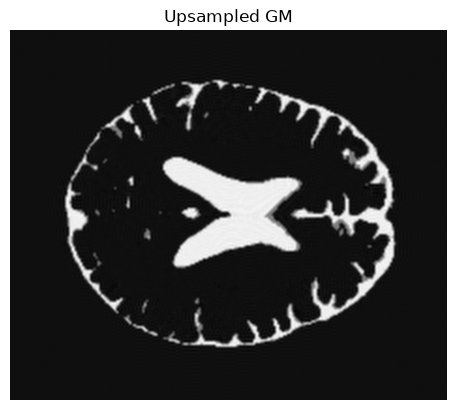

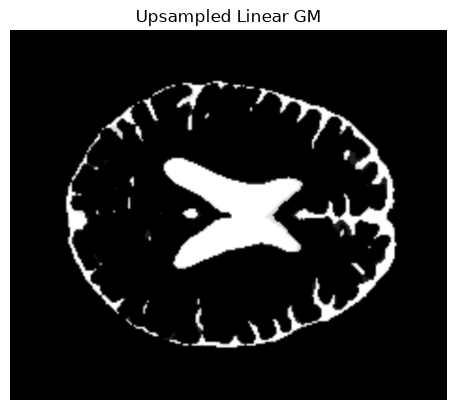

In [6]:
one_hot = F.one_hot(torch.from_numpy(seg).long(), num_classes=4).float()
np_onehot = one_hot.numpy()

print("Seg shape:", np_onehot.shape)
# show the one-hot channels
middle_slice = np_onehot.shape[2] // 2
fig, ax = plt.subplots(1, np_onehot.shape[-1]-1, figsize=(15, 5))
for i in range(np_onehot.shape[-1]):
    if i == 0:
        continue # skip background
    ax[i-1].imshow(np_onehot[..., i][..., middle_slice], cmap='gray')
    ax[i-1].set_title(f'Label {i}')
    ax[i-1].axis('off')
plt.show()
    


gm = np_onehot[..., 1]
upsampled_gm = _sinc_upsample_smooth(torch.from_numpy(gm), factor=4, sigma_mm=0.5, out_voxel_mm=0.25).numpy()
upsampled_linear_gm = linear_upsample_smooth(torch.from_numpy(gm), factor=4, sigma_mm=0.5, out_voxel_mm=0.25).numpy()


middle_slice = upsampled_gm.shape[2] // 2
plt.imshow(upsampled_gm[..., middle_slice], cmap='gray')
plt.title(f'Upsampled GM')
plt.axis('off')
plt.show()

plt.imshow(upsampled_linear_gm[..., middle_slice], cmap='gray')
plt.title(f'Upsampled Linear GM')
plt.axis('off')
plt.show()


